# ML-KEM-768 poly_tomsg CPA (비밀키 ŝ 전체 계수 분석)

## 연구 목표와 위치

이 노트북은 ML-KEM-768 decapsulation의 **B 누출 지점인 `poly_tomsg`**를 저장된 실측 전력 트레이스로 분석한다. 앞선 A 노트북이 NTT 도메인 `basemul`의 곱셈을 다룬다면, 여기서는 복호화 과정에서 메시지 비트로 변환되기 직전의 다항식 계수 `mp[j]`가 타깃이다. 캡처는 `mlkem-trace-poly_tomsg.ipynb`에서 별도로 수집했으며, B 파일은 A 파일과 행별 paired 데이터가 아니다.

이 노트북의 목적은 두 단계다. 먼저 단일 비밀계수에 대한 CPA feasibility를 재현해 누출 모델과 POI를 살펴본다. 다음으로 동일한 모델을 768개 비밀 NTT 계수에 반복 적용하는 연구용 기준선/시도를 제공한다. 분석은 모든 경우 저장된 `.npz`에서 시작하며 별도 캡처 장비 연결은 필요하지 않다.

## B 연산의 의미와 CPA 모델

복호화는 암호문 `ct=(u,v)`와 비밀 NTT 벡터 `ŝ`를 사용해 `mp = Reduce(v − InvNTT(ŝᵀ·NTT(u)))` 형태의 중간값을 만든다. clean 구현에서는 `poly_tomsg`가 `mp`의 계수를 순회하며 각 값을 메시지 비트로 반올림·패킹한다. 공격 가설은 `poly_tomsg`의 입력 계수가 연산 직전에 레지스터로 읽힐 때 그 32-bit 값의 Hamming weight가 전력에 반영된다는 것이다.

계수 후보 `g`가 주어지면 저장 암호문별 `mp`를 재구성한다. 후보별 HW 벡터와 같은 행의 측정 파형을 대응시켜 Pearson 상관을 구한다. 트레이스 파형을 먼저 평균내지 않는다. 출력 계수와 시간 창을 고정해 후보 순위를 계산하므로, 분석 조건은 결과와 함께 보고해야 한다.

## 기본 설정 및 재현성

기본 입력은 `capture_target=poly_tomsg` 메타데이터가 있는 일반 B 캡처다. 현재 `TRACE_LIMIT=100`은 빠른 실험을 위해 첫 100개 행만 취한다. 각 `traces[t]`와 `ct[t]`는 반드시 같은 캡처 행이어야 한다. `dk`는 중간값 재현과 정답 채점에 쓰이며, 키 바이트나 전체 비밀계수는 노트북 출력·블로그 그림에 공개하지 않는다.

초기 정수 포팅은 clean 구현의 NTT·Montgomery·Barrett 연산과 `poly_tomsg` 변환을 맞춘다. 포팅이 맞는지 검사하는 것은 공격 성능과 별개의 단계다. 선택적 `kyber_py` cross-check는 설치된 때만 메시지 결과를 비교하며, 패키지가 없으면 건너뛴다.

## 가장 중요한 해석 제한

기본 `ORACLE_BASELINE=True` 전체 스윕은 타깃 외 다른 767개 계수를 실제 `dk` 값으로 고정하고, 정답 타깃 모델의 상관 프로파일로 POI를 고른다. 따라서 768/768 rank 0 또는 정답 일치가 출력되어도 **blind 전체 키 복구가 아니다.** 이 결과는 “다른 계수들이 이미 알려진 조건에서, 특정 한 계수의 누출과 모델이 얼마나 잘 맞는가”를 보여주는 oracle-assisted 진단이다.

`ORACLE_BASELINE=False`는 0으로 초기화한 현재 추정 키를 바탕으로 계수별 좌표하강을 시도한다. 정답 비교와 rank를 공격 루프에서 사용하지 않도록 분리했지만, 오차 전파·POI 선택 편향·고정 출력 계수 문제는 남아 있고 성공이 검증된 공격이 아니다. blind 실험의 성능은 별도 키와 독립 캡처에서 확인하기 전까지 미확정으로 다룬다.

## 1. B 트레이스 `.npz` 불러오기

이 로더는 `mlkem-trace-poly_tomsg.ipynb`가 저장한 일반 B 캡처를 선택하고 `traces`, `ct`, `dk` 필드와 `capture_target`을 검사한다. TVLA 파일(`waves/labels`)이나 분석 산출물은 일반 CPA 파형처럼 해석하지 않도록 후보에서 제외한다. 완성된 zip만 고르는 검사도 하므로 저장 중인 파일을 읽는 문제를 피한다.

`TRACE_LIMIT=100`이면 원본 파일에서 첫 100개 파형과 같은 행의 암호문을 함께 자른다. 이 설정은 실행 시간을 줄이는 대신 통계량을 줄인다. `.npz` 메타데이터의 scheme, 구현, 최적화, 샘플 수, ADC 배율 및 capture target을 같이 확인해 보고서에 캡처 조건을 명시한다.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

TRACE_PATH = "../traces/mlkem768-clean-O3-poly_tomsg-20261030-053826.npz"
TRACE_LIMIT = 100


In [ ]:
with np.load(TRACE_PATH) as data:
    traces_full = data["traces"].astype(np.float32)
    ciphertexts_full = data["ct"].astype(np.uint8)
    secret_key = data["dk"].tobytes()

trace_count = min(TRACE_LIMIT, len(traces_full))
traces = traces_full[:trace_count]
ciphertexts = ciphertexts_full[:trace_count]


## 2. PQClean clean 정수 연산 포팅

CPA 입력 모델은 수학적 잔여값이 아니라 MCU에서 실제로 표현·처리된 값에 의존한다. 따라서 `int16_t` wrap, Montgomery/Barrett reduction, NTT 계수 순서, centered representative와 `poly_tomsg` 내부의 unsigned 변환을 그대로 반영한다. 아래 함수는 동일한 NTT/Montgomery 기반을 A 분석과 공유하지만, B의 최종 타깃은 곱셈 결과가 아니라 `mp` 입력이다.

ML-KEM-768에서 `.npz`의 키·암호문 길이는 각각 2400·1088바이트로 검사된다. 구현 포팅의 테스트는 연산 재현성만을 확인하며, 전력 상관이 유의미하거나 비밀키를 blind로 복구했다는 근거와 구별한다.

In [ ]:
import numpy as np                              # 수치 계산

Q, QINV, N, K = 3329, -3327, 256, 3               # q=모듈러스, QINV=q^-1 mod 2^16, N=계수수, K=다항식수(768)
ZETAS = [                                         # NTT twiddle 상수 128개 (ntt.c와 동일해야 b̂ 재현됨)
    -1044, -758, -359, -1517, 1493, 1422, 287, 202, -171, 622, 1577, 182, 962, -1202,
    -1474, 1468, 573, -1325, 264, 383, -829, 1458, -1602, -130, -681, 1017, 732, 608,
    -1542, 411, -205, -1571, 1223, 652, -552, 1015, -1293, 1491, -282, -1544, 516, -8,
    -320, -666, -1618, -1162, 126, 1469, -853, -90, -271, 830, 107, -1421, -247, -951,
    -398, 961, -1508, -725, 448, -1065, 677, -1275, -1103, 430, 555, 843, -1251, 871,
    1550, 105, 422, 587, 177, -235, -291, -460, 1574, 1653, -246, 778, 1159, -147, -777,
    1483, -602, 1119, -1590, 644, -872, 349, 418, 329, -156, -75, 817, 1097, 603, 610,
    1322, -1285, -1465, 384, -1215, -136, 1218, -1335, -874, 220, -1187, -1659, -1185,
    -1530, -1278, 794, -1510, -854, -870, 478, -108, -308, 996, 991, 958, -1460, 1522, 1628,
]

def to_i16(x):                                      # 값을 int16 범위로 wrap (보드가 int16_t라 똑같이 잘라야 함)
    return ((int(x) + 0x8000) & 0xFFFF) - 0x8000  # +2^15 후 2^16 마스크 후 -2^15 = 부호있는 16비트

def montgomery_reduce(a):                         # a * R^-1 mod q (R=2^16) — reduce.c와 비트 단위 동일
    t = to_i16(to_i16(a) * QINV)                      # t = (int16_t)((int16_t)a * QINV)
    return (int(a) - t * Q) >> 16                 # (a - t*q) >> 16 (산술 시프트)

def fqmul(a, b):                                  # NTT 도메인 곱 = mont(a*b)
    return montgomery_reduce(to_i16(a) * to_i16(b))   # 두 int16을 곱해 몽고메리 리덕션

def barrett_reduce(a):                            # poly_reduce: ntt 뒤 보드가 적용하는 reduce (대표값 맞춤)
    v = ((1 << 26) + Q // 2) // Q                 # barrett 상수 round(2^26 / q)
    t = (v * to_i16(a) + (1 << 25)) >> 26           # t = round(a / q)
    return to_i16(to_i16(a) - to_i16(t * Q))            # a - t*q (centered 대표값)

def ntt(r):                                       # 정방향 NTT (normal -> bitreversed order)
    r = [to_i16(x) for x in r]                      # 입력을 int16로 (보드와 동일 표현)
    k, length = 1, 128                            # k=zeta 인덱스, length=butterfly 거리
    while length >= 2:                            # 길이 128,64,...,2 로 7단
        start = 0                                 # 각 단의 그룹 시작 위치
        while start < 256:                        # 256계수를 그룹 단위로 훑음
            zeta = ZETAS[k]; k += 1               # 이 그룹의 twiddle
            for j in range(start, start + length):# 그룹 내 butterfly
                t = fqmul(zeta, r[j + length])    # 짝 계수에 twiddle 곱
                r[j + length] = to_i16(r[j] - t)    # 아래쪽 = 위 - t
                r[j] = to_i16(r[j] + t)             # 위쪽 = 위 + t
            start = j + length + 1                # 다음 그룹 시작 (start + 2*length)
        length >>= 1                              # 다음 단은 거리 절반
    return r                                       # NTT 결과 리스트 반환

def poly_frombytes(a):                            # dk의 12비트 패킹을 NTT 비밀키 계수로 복원 (0..q-1)
    r = [0] * N                                   # 256계수 버퍼
    for i in range(N // 2):                       # 3바이트가 2계수
        r[2*i]   = ((a[3*i] >> 0) | (a[3*i+1] << 8)) & 0xFFF   # 하위 12비트 = 계수 0
        r[2*i+1] = ((a[3*i+1] >> 4) | (a[3*i+2] << 4)) & 0xFFF # 상위 12비트 = 계수 1
    return r                                       # ŝ 한 다항식

def polyvec_decompress_vec(a):                    # c1 압축(du=10) 해제: 320바이트 -> 256 normal 계수
    r = [0] * N; p = 0                            # r=출력, p=바이트 포인터
    for j in range(N // 4):                       # 5바이트가 4계수(10비트×4)
        t = ((a[p] | a[p+1] << 8),                # 10비트 값 4개 추출
             (a[p+1] >> 2 | a[p+2] << 6),
             (a[p+2] >> 4 | a[p+3] << 4),
             (a[p+3] >> 6 | a[p+4] << 2))
        p += 5                                    # 다음 5바이트로
        for kk in range(4):                       # 4계수 각각 Decompress
            r[4*j+kk] = ((t[kk] & 0x3FF) * Q + 512) >> 10   # round(q/2^10 * t)
    return r                                       # u 한 다항식 (normal 도메인)

def bhat_from_ct(ct):                             # 아는 값 b̂ = poly_ntt(Decompress(c1)) — 보드 poly_ntt와 동일
    out = []                                      # 다항식 K개
    for i in range(K):                            # 각 u 벡터 성분
        coeffs = polyvec_decompress_vec(ct[320*i:320*(i+1)])  # c1의 i번째 320바이트 -> u_i
        coeffs = ntt(coeffs)                      # 정방향 NTT (반환값 사용)
        out.append([barrett_reduce(x) for x in coeffs])       # ntt 뒤 poly_reduce 적용
    return out                                     # b̂ (NTT 도메인)

def shat_from_dk(dk):                             # 정답 비밀키 ŝ (채점용) — dk 앞 384*K 바이트
    return [poly_frombytes(dk[384*i:384*(i+1)]) for i in range(K)]  # 다항식 K개



## 3. `indcpa_dec`에서 B 입력 계수 재구성

각 캡처 행의 1088-byte 암호문은 `u` 영역 960 bytes와 `v` 영역 128 bytes로 나뉜다. 코드 흐름은 다음 순서로 clean 구현을 재현한다.

1. 세 `u_i` 벡터를 압축 해제하고 각각 NTT로 변환한다.
2. 비밀 벡터 `ŝ`와 `NTT(u)`의 계수쌍 `basemul`을 수행해 누산한다.
3. PQClean의 int16 덧셈/reduction 순서에 맞춘 후 inverse NTT를 적용한다.
4. `v`를 압축 해제하고 누산된 값을 빼며, 실제 `poly_reduce` representative를 만든다.
5. 그 결과 `mp`가 B의 `poly_tomsg` 입력이다.

이 순서는 측정 데이터마다 암호문이 다르므로 행별 `mp[t,j]`도 달라진다. 다음 단계의 CPA 후보 모델은 각 입력 행에 해당하는 중간값을 만들어 같은 행의 측정 파형과 연결한다.

### 실습 B1 — `ct → mp` 계산을 층별로 읽기

`decrypt_mp_with_secret`은 공격 코드가 아니라, 후보 비밀키 아래 각 암호문이 만들 `poly_tomsg` 입력을 계산하는 함수야.

1. 암호문 앞 960바이트를 세 개의 320바이트 `u_i`로 나눈다.
2. 각 `u_i`를 압축 해제하고 `ntt_vec`을 적용한다.
3. `basemul_vec(secret[i], NTT(u_i))`를 누산한다.
4. 누산 결과에 inverse NTT를 적용하고, 끝의 128바이트 `v`를 압축 해제해 뺀다.
5. `barrett_vec` 결과가 각 행의 `mp`다.

여기서 `wrap16`, `fqmul_vec`, `barrett_vec`는 `int16_t` 동작을 행렬 입력에도 유지하려고 필요한 구현 세부사항이야. 벡터화는 여러 트레이스를 한 번에 계산하지만, 연산의 순서를 바꾸면 안 돼.

**체크:** 이 함수의 `secret`이 틀리면 여러 `mp` 계수와 그에 따른 메시지 비트가 달라질 수 있어. 그래서 B는 A의 단일 곱셈 CPA처럼 계수 하나만 독립적으로 모델링하기 어렵다.


In [4]:
def wrap16(values):
    return ((np.asarray(values, dtype=np.int64) + 32768) & 65535) - 32768


def fqmul_vec(left, right):
    product = wrap16(left) * wrap16(right)
    low = wrap16(product)
    temp = wrap16(low * QINV)
    return wrap16((product - temp * Q) >> 16)


def barrett_vec(values):
    values = wrap16(values)
    qmul = ((1 << 26) + Q // 2) // Q
    scaled = (qmul * values + (1 << 25)) >> 26
    return wrap16(values - scaled * Q)


def ntt_vec(values):
    values = wrap16(values.copy())
    zeta_index = 1
    for size in (128, 64, 32, 16, 8, 4, 2):
        for start in range(0, 256, 2 * size):
            upper = values[:, start:start + size].copy()
            butterfly = fqmul_vec(ZETAS[zeta_index], values[:, start + size:start + 2 * size])
            zeta_index += 1
            values[:, start:start + size] = wrap16(upper + butterfly)
            values[:, start + size:start + 2 * size] = wrap16(upper - butterfly)
    return barrett_vec(values)


def basemul_vec(secret, public):
    result = np.empty_like(public)
    for block in range(64):
        for offset, twiddle in ((0, ZETAS[64 + block]), (2, -ZETAS[64 + block])):
            pair = 4 * block + offset
            a0, a1 = secret[pair], secret[pair + 1]
            b0, b1 = public[:, pair], public[:, pair + 1]
            even = wrap16(fqmul_vec(fqmul_vec(a1, b1), twiddle) + fqmul_vec(a0, b0))
            odd = wrap16(fqmul_vec(a0, b1) + fqmul_vec(a1, b0))
            result[:, pair] = even
            result[:, pair + 1] = odd
    return result


def invntt_vec(values):
    values = wrap16(values.copy())
    zeta_index = 127
    for size in (2, 4, 8, 16, 32, 64, 128):
        for start in range(0, 256, 2 * size):
            upper = values[:, start:start + size].copy()
            lower = values[:, start + size:start + 2 * size].copy()
            values[:, start:start + size] = barrett_vec(upper + lower)
            values[:, start + size:start + 2 * size] = fqmul_vec(ZETAS[zeta_index], wrap16(lower - upper))
            zeta_index -= 1
    return fqmul_vec(values, 1441)


def decrypt_mp_with_secret(ciphertexts, secret):
    trace_count = len(ciphertexts)
    accumulated = np.zeros((trace_count, 256), dtype=np.int64)
    for poly_index in range(3):
        start = 320 * poly_index
        compressed_u = [row[start:start + 320].astype(np.int64) for row in ciphertexts]
        public_ntt = ntt_vec(np.array([polyvec_decompress_vec(row) for row in compressed_u], dtype=np.int64))
        product = basemul_vec(secret[poly_index], public_ntt)
        accumulated = product if poly_index == 0 else wrap16(accumulated + product)
    accumulated = invntt_vec(barrett_vec(accumulated))

    compressed_v = ciphertexts[:, 960:1088].astype(np.int64)
    decompressed_v = np.empty_like(accumulated)
    decompressed_v[:, 0::2] = ((compressed_v & 15) * Q + 8) >> 4
    decompressed_v[:, 1::2] = ((compressed_v >> 4) * Q + 8) >> 4
    return barrett_vec(wrap16(decompressed_v - accumulated))


def poly_tomsg_output(mp):
    raw_words = np.asarray(mp).astype(np.uint32)
    arithmetic = ((raw_words << np.uint32(1)) + np.uint32(1665)) * np.uint32(80635)
    return ((arithmetic >> np.uint32(28)) & np.uint32(1)).astype(np.uint8)


def decrypt_intermediates(ciphertexts, decapsulation_key):
    secret = np.asarray(shat_from_dk(decapsulation_key), dtype=np.int64)
    mp = decrypt_mp_with_secret(ciphertexts, secret)
    message_bits = poly_tomsg_output(mp)
    messages = np.packbits(message_bits, axis=1, bitorder="little")
    return mp, message_bits, messages


### 실습 B2 — 한 비밀계수 후보가 `mp`에 미치는 영향

`build_secret_sensitivity`는 기준 비밀 벡터에서 타깃 계수만 0으로 둔 경우와 1로 둔 경우를 계산해 차이 `Δ`를 구해. 이후 후보 `g`의 출력 계수는 `mp_g = (mp_0 + g·Δ) mod q`로 만든다.

이 방식은 `mp`가 해당 비밀 계수에 대해 선형이라는 뜻이지, 전체 `poly_tomsg` 출력이 비밀계수 하나에만 의존한다는 뜻은 아니야. 기준 `secret_reference`의 나머지 계수들이 결과에 그대로 들어가.

`build_tomsg_input_models`는 centered `mp`를 C 코드의 `uint32_t` 비트 패턴으로 바꾸고, 4바이트 각각의 Hamming weight를 더해 트레이스별 누출 모델을 만든다. 이는 “입력 레지스터 값의 HW 누출”이라는 가설이며, 실제 MCU 누출이 반드시 그 모델을 따른다는 보장은 없어.


In [5]:
BYTE_HAMMING_WEIGHT = np.array([value.bit_count() for value in range(256)], dtype=np.uint8)

def build_secret_sensitivity(ciphertexts, secret_reference, secret_vector, secret_coefficient):
    """한 계수를 0과 1로 바꿔 기준 mp와 계수의 모듈러 영향을 구한다."""
    secret_zero = secret_reference.copy()
    secret_unit = secret_reference.copy()
    secret_zero[secret_vector, secret_coefficient] = 0
    secret_unit[secret_vector, secret_coefficient] = 1
    mp_zero = decrypt_mp_with_secret(ciphertexts, secret_zero).astype(np.int64)
    mp_unit = decrypt_mp_with_secret(ciphertexts, secret_unit).astype(np.int64)
    coefficient_influence = (mp_unit - mp_zero) % Q
    return mp_zero, coefficient_influence


def build_candidate_mp(mp_base, coefficient_influence, candidate_values, output_coefficient):
    """한 출력 계수에서 비밀계수 후보별 mp를 만들고 C의 centered 표현으로 바꾼다."""
    base_values = np.asarray(mp_base, dtype=np.int64)[:, output_coefficient]
    influence_values = np.asarray(coefficient_influence, dtype=np.int64)[:, output_coefficient]
    candidates = np.asarray(candidate_values, dtype=np.int64).reshape(-1)
    candidate_mp = (base_values[None, :] + candidates[:, None] * influence_values[None, :]) % Q
    return ((candidate_mp + Q // 2) % Q) - Q // 2


def build_tomsg_input_models(centered_mp_values):
    """poly_tomsg 입력의 uint32 비트 패턴을 바이트 Hamming weight 모델로 바꾼다."""
    input_words = np.asarray(centered_mp_values, dtype=np.int64).astype(np.uint32)
    input_bytes = input_words.astype("<u4", copy=False).view(np.uint8).reshape(input_words.shape + (4,))
    return BYTE_HAMMING_WEIGHT[input_bytes].sum(axis=-1).astype(np.float64)


def calculate_pearson_correlations(candidate_models, measured_traces):
    """각 후보 누출 모델과 측정 파형 샘플 사이의 Pearson 상관을 계산한다."""
    models = np.asarray(candidate_models, dtype=np.float64)
    traces_for_correlation = np.asarray(measured_traces, dtype=np.float64)
    if traces_for_correlation.ndim == 1:
        traces_for_correlation = traces_for_correlation[:, None]
    if models.ndim != 2 or traces_for_correlation.ndim != 2 or models.shape[1] != traces_for_correlation.shape[0]:
        raise ValueError(f"CPA 배열 shape 불일치: models={models.shape}, traces={traces_for_correlation.shape}")
    centered_models = models - models.mean(axis=1, keepdims=True)
    centered_traces = traces_for_correlation - traces_for_correlation.mean(axis=0, keepdims=True)
    model_norms = np.sqrt((centered_models ** 2).sum(axis=1)) + 1e-12
    trace_norms = np.sqrt((centered_traces ** 2).sum(axis=0)) + 1e-12
    return (centered_models @ centered_traces) / (model_norms[:, None] * trace_norms[None, :])


def summarize_candidate_scores(correlation):
    """후보마다 구간 내 최대 절대 상관과 해당 샘플 인덱스를 반환한다."""
    absolute_correlation = np.abs(correlation)
    score_per_candidate = absolute_correlation.max(axis=1)
    peak_per_candidate = absolute_correlation.argmax(axis=1)
    return score_per_candidate, peak_per_candidate


## 4. 전체 `poly_tomsg` 입력 재현 및 검증

`decrypt_intermediates`는 저장된 `dk`와 각 행의 `ct`로 `mp`, unsigned 산술 중간값, 메시지 비트 및 복호화 메시지를 재현한다. 단일 비밀계수의 counterfactual 모델은 타깃 계수만 0 또는 1로 바꾼 두 계산의 모듈러 차이로 만든다. 후보 `g`의 `mp`는 `mp_zero + g·influence (mod q)`로 구성한다. 이 선형 영향 모델이 실제 키를 대입했을 때 기준 `mp`를 재현하는지 assertion으로 확인한다.

설치되어 있으면 독립 `kyber_py` 구현의 복호화 메시지와 행별 비교를 추가한다. 그 비교는 CPU 소프트웨어 중간값 포팅의 교차검증이며, 측정 전력의 CPA 성공이나 공격 현실성을 입증하지는 않는다.

In [6]:
mp_true, message_bits_true, decrypted_messages = decrypt_intermediates(ciphertexts, secret_key)
secret_coefficients = np.asarray(shat_from_dk(secret_key), dtype=np.int64)
SECRET_VEC = 0
SECRET_COEFF = 15
OUTPUT_COEFF = 202
true_secret_coeff = int(secret_coefficients[SECRET_VEC, SECRET_COEFF])
mp_zero, coefficient_influence = build_secret_sensitivity(ciphertexts, secret_coefficients, SECRET_VEC, SECRET_COEFF)
predicted_true_mp = build_candidate_mp(mp_zero, coefficient_influence, [true_secret_coeff], OUTPUT_COEFF)
assert np.array_equal(predicted_true_mp[0], mp_true[:, OUTPUT_COEFF]), "정답 후보 중간값 불일치"
print("target secret coordinate:", (SECRET_VEC, SECRET_COEFF), "true coefficient:", true_secret_coeff)
print("reconstructed mp:", mp_true.shape, "message bits:", message_bits_true.shape)

# Optionally cross-check exact messages against the independent kyber-py implementation.
try:
    from kyber_py.ml_kem import ML_KEM_768
except ImportError:
    print("kyber-py unavailable: reference-message cross-check skipped")
else:
    reference_messages = np.array([np.frombuffer(ML_KEM_768._k_pke_decrypt(secret_key[:1152], row.tobytes()), dtype=np.uint8) for row in ciphertexts])
    assert np.array_equal(reference_messages, decrypted_messages), "PQClean port's poly_tomsg bits disagree with kyber-py"
    print("reference decapsulation message check:", len(reference_messages), "/", trace_count, "matched")


target secret coordinate: (0, 15) true coefficient: 2760
reconstructed mp: (100, 256) message bits: (100, 256)
reference decapsulation message check: 100 / 100 matched


## 5. 단일계수 CPA feasibility

기본 단일계수 대상은 `SECRET_VEC=0`, `SECRET_COEFF=15`이며, 고정된 출력 계수 `OUTPUT_COEFF=202`와 B 샘플 창 `SAMPLE_WINDOW=(5630,5661)`을 사용한다. 계수 후보 `g=0..3328`별로 `mp` 입력을 재구성하고, C에서 centered int16 값이 `uint32_t`로 변환될 때의 32-bit 비트 패턴 Hamming weight를 예측 누출로 삼는다. 각 후보의 HW 벡터와 창 안 파형을 Pearson 상관해 후보 점수를 구한다.

이 출력 계수와 샘플 창은 선행 known-key 분석을 참고해 고정한 조건이다. 정답 키로 다른 767개 계수를 고정한 단일계수 실험이므로, 높은 상관/ rank 0은 feasibility 결과이지 blind 전체 복구 결과가 아니다. 그래프의 상위 후보와 peak 샘플을 함께 읽고, 다른 창·캡처에서도 재현되는지 검증해야 한다.

### 실습 B3 — 3329개 후보 점수와 rank

순서대로 추적해 봐: (1) 각 후보의 `mp`를 만든다, (2) 각 `mp`를 HW 모델로 변환한다, (3) 선택한 31개 샘플과 후보 모델의 Pearson 상관을 구한다, (4) 후보별 최고 절댓값 상관으로 점수를 정한다, (5) 알려진 실제 계수의 rank를 계산한다.

`OUTPUT_COEFF=202`는 `mp` 다항식에서 관측 모델로 사용할 출력 위치고, `SAMPLE_WINDOW`는 시간축 구간이야. 둘은 서로 다른 인덱스다. `SECRET_COEFF=15`는 추정할 비밀 계수 위치다.

**해석 연습:** 여기서 true coefficient는 후보 점수 계산에 넣지 않고 rank를 사후 채점하는 데 쓴다. 하지만 `mp_zero`와 `coefficient_influence`를 만들 때 다른 비밀계수의 참값을 사용했다. 그러므로 이 단일계수 rank 0은 oracle 조건의 feasibility 결과이지, 타깃 키만으로 수행한 blind 복구가 아니야.


In [7]:
SAMPLE_WINDOW = (5630, 5661)
key_guesses = np.arange(Q, dtype=np.int64)
predicted_mp = build_candidate_mp(mp_zero, coefficient_influence, key_guesses, OUTPUT_COEFF)
assert np.array_equal(predicted_mp[true_secret_coeff], mp_true[:, OUTPUT_COEFF]), "정답 후보 중간값 불일치"
model = build_tomsg_input_models(predicted_mp)
sample_start, sample_stop = SAMPLE_WINDOW
trace_window = traces[:, sample_start:sample_stop].astype(np.float64)
correlation = calculate_pearson_correlations(model, trace_window)
score_per_guess, peak_column_per_guess = summarize_candidate_scores(correlation)
rank_order = np.argsort(score_per_guess)[::-1]
true_rank = int(np.flatnonzero(rank_order == true_secret_coeff)[0])
best_guess = int(rank_order[0])
true_peak = int(peak_column_per_guess[true_secret_coeff] + sample_start)
print("true coeff:", true_secret_coeff, "best guess:", best_guess, "rank:", true_rank)
print("true score:", float(score_per_guess[true_secret_coeff]), "peak sample:", true_peak)
print("top 5:", [(int(guess), float(score_per_guess[guess])) for guess in rank_order[:5]])


true coeff: 2760 best guess: 2760 rank: 0
true score: 0.7321000246530261 peak sample: 5644
top 5: [(2760, 0.7321000246530261), (1294, 0.424917595000676), (937, 0.3957317534401576), (1443, 0.38986779701703894), (748, 0.3823052659898703)]


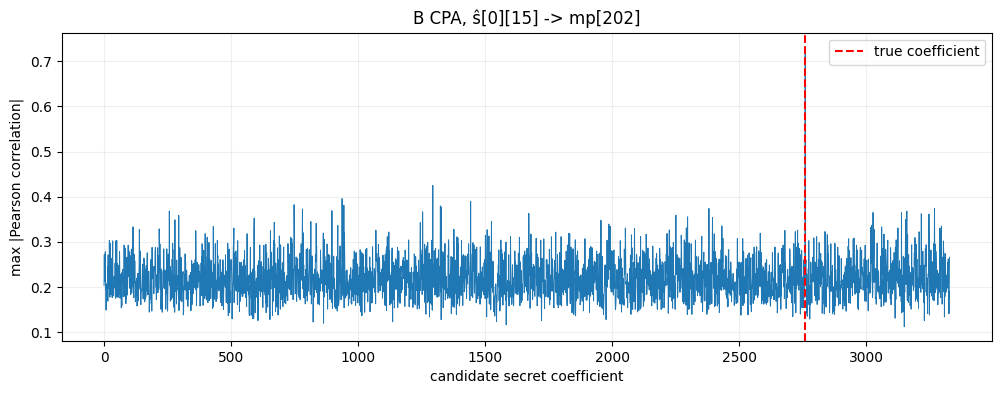

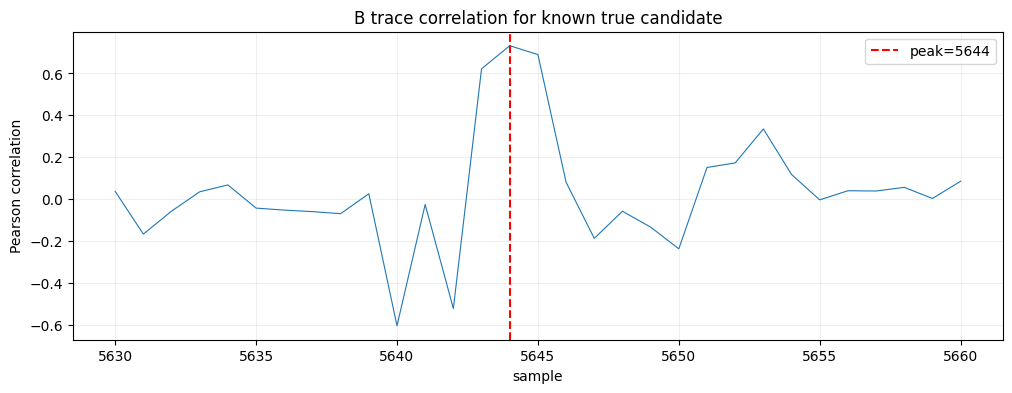

In [8]:
plt.figure(figsize=(12, 4))                     # 후보 점수 그림
plt.plot(key_guesses, score_per_guess, linewidth=0.7) # 모든 secret 후보 점수
plt.axvline(true_secret_coeff, color="red", linestyle="--", label="true coefficient") # 실제 키 위치
plt.xlabel("candidate secret coefficient")      # x축 후보값
plt.ylabel("max |Pearson correlation|")          # y축 CPA score
plt.title(f"B CPA, ŝ[{SECRET_VEC}][{SECRET_COEFF}] -> mp[{OUTPUT_COEFF}]") # 타깃 표기
plt.legend()                                     # 정답 선 범례
plt.grid(alpha=0.2)                              # 격자
plt.show()                                       # 그래프 출력

plt.figure(figsize=(12, 4))                     # 정답 후보의 시간 상관 그래프
plt.plot(np.arange(sample_start, sample_stop), correlation[true_secret_coeff], linewidth=0.8) # signed correlation
plt.axvline(true_peak, color="red", linestyle="--", label=f"peak={true_peak}") # 선택된 POI
plt.xlabel("sample")                            # x축 시간 샘플
plt.ylabel("Pearson correlation")                # y축 상관계수
plt.title("B trace correlation for known true candidate") # 설명 제목
plt.legend()                                     # peak 범례
plt.grid(alpha=0.2)                              # 격자
plt.show()                                       # 그래프 출력


## 6. 트레이스 수별 known-key rank

첫 `n`개 캡처를 사용해 동일한 단일계수 모델의 순위 변화를 확인한다. 여기서는 known-key 기준으로 타깃의 실제 계수와 보정된 피크를 사용하므로, 곡선은 이 알려진 조건에서 트레이스 수에 따른 분리도를 나타낸다. 시험한 목록에서 처음 rank 0이 나온 값은 최소 필요 수량을 뜻하지 않으며, 독립 키·창 선택을 포함한 blind 공격 비용과도 다르다.

N=  20: rank=3, true score=0.7297
N=  50: rank=0, true score=0.7127
N= 100: rank=0, true score=0.7321


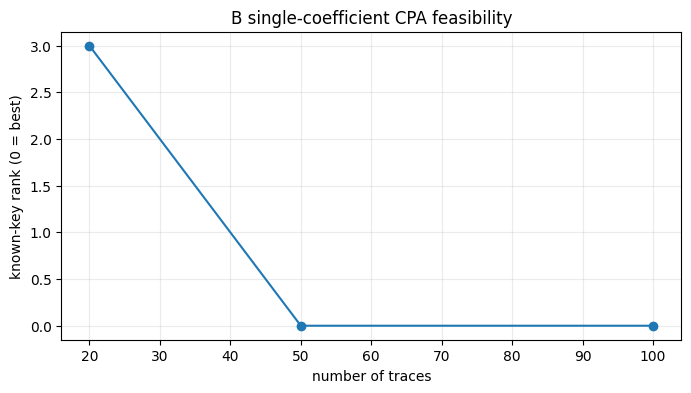

In [9]:
trace_counts = [count for count in (20, 50, 100, 200, 500, trace_count) if 2 <= count <= trace_count]
trace_counts = sorted(set(trace_counts))
rank_by_trace_count = []
fixed_poi_trace = traces[:, true_peak].astype(np.float64)
for count in trace_counts:
    model_prefix = model[:, :count]
    trace_prefix = fixed_poi_trace[:count]
    prefix_correlation = calculate_pearson_correlations(model_prefix, trace_prefix)[:, 0]
    prefix_score = np.abs(prefix_correlation)
    prefix_rank = int(np.sum(prefix_score > prefix_score[true_secret_coeff]))
    rank_by_trace_count.append(prefix_rank)
    print(f"N={count:4d}: rank={prefix_rank}, true score={prefix_score[true_secret_coeff]:.4f}")

plt.figure(figsize=(8, 4))
plt.plot(trace_counts, rank_by_trace_count, "o-")
plt.xlabel("number of traces")
plt.ylabel("known-key rank (0 = best)")
plt.title("B single-coefficient CPA feasibility")
plt.grid(alpha=0.25)
plt.show()


## 7. 전체 768계수 CPA 연구 실험

각 타깃 비밀계수에 대해 3329개 후보를 평가하고, 고정된 `OUTPUT_COEFF`와 B 샘플 창에서 raw `poly_tomsg` 입력 HW 모델의 Pearson 상관을 계산한다. 대형 `(후보, 트레이스, 출력 계수)` 배열을 한꺼번에 만들지 않고, 출력 계수 하나에 해당하는 후보×트레이스 배열만 생성해 메모리 사용량을 제한한다. 진행상황은 64개 좌표마다 출력하고 마지막에 처리 수, 신호 미확인 수, rank 0 및 정답 일치 요약을 낸다.

기본값 `ORACLE_BASELINE=True`에서는 현재 타깃 이외의 모든 계수를 정답으로 고정하고, 정답 타깃 leakage profile의 peak를 POI로 고른다. 이런 모드에서의 추정·rank는 known-key oracle 기준선이며 blind가 아니다. `False`에서는 정답으로 다른 계수를 고정하지 않고 현재 추정치를 사용하지만, 초기값 0과 coordinate descent는 검증되지 않은 연구용 시도다. 한 좌표의 오답이 후속 좌표 추정에 전파될 수 있다.

현재 구현은 고정된 단일 출력 계수와 샘플 창을 사용한다. 따라서 좋은 결과가 나오더라도 그 결과가 다른 출력 인덱스, 키, 캡처 배치에서 반복되는지 따로 확인해야 한다. 전체 키 복구 주장은 고정 POI/창을 독립 기준으로 정하고, 여러 독립 키에서 재현할 때까지 보류한다.

### 실습 B4 — 전체 스윕: 무엇이 oracle이고 무엇이 blind인가?

코드를 실행하기 전에 위 설정을 확인해. `ORACLE_BASELINE=True`가 기본값이고, `COEFFICIENT_LIMIT`은 시험할 좌표 수야. 기본 전체 실행은 각 좌표마다 다음을 반복해.

1. 현재 기준 비밀 벡터에서 타깃 좌표의 영향량을 계산한다.
2. `g=0..3328` 후보별 `mp`와 HW 모델을 만든다.
3. 고정된 `OUTPUT_COEFF`의 샘플 창에서 후보-파형 상관을 계산한다.
4. **oracle 모드:** 타깃의 실제 값으로 샘플 위치를 고르고, 다른 767개 실제 계수를 기준값으로 사용한다.
5. **blind 시도:** 실제 계수 대신 현재 추정 행렬을 쓰고, 가장 높은 후보/샘플을 선택한 뒤 추정값을 다음 좌표에 반영한다.

`False`로 설정하는 것만으로 공격이 검증되는 건 아니야. 좌표하강은 초기 추정 오류를 다음 중간값에 전파할 수 있고, 한 출력 계수와 창만 쓰는 제한도 남아 있어. 기존 100개 파형의 oracle 결과를 blind 성공으로 바꾸어 읽으면 안 돼.


In [10]:
# ── 전체 768개 계수 CPA: oracle 기준선 / blind 실험 ──
ORACLE_BASELINE = True
COEFFICIENT_LIMIT = K * N
MAX_PASSES = 1
MIN_CORRELATION = 0.20

secret_guess_matrix = secret_coefficients.copy() if ORACLE_BASELINE else np.zeros_like(secret_coefficients)
key_recovery_records = []
trace_window = traces[:, SAMPLE_WINDOW[0]:SAMPLE_WINDOW[1]].astype(np.float64)

for recovery_pass in range(MAX_PASSES):
    for coefficient_index in range(min(K * N, COEFFICIENT_LIMIT)):
        secret_vector = coefficient_index // N
        secret_coefficient = coefficient_index % N
        true_coefficient = int(secret_coefficients[secret_vector, secret_coefficient]) if ORACLE_BASELINE else -1
        reference_secret = secret_coefficients if ORACLE_BASELINE else secret_guess_matrix
        mp_base, coefficient_delta = build_secret_sensitivity(ciphertexts, reference_secret, secret_vector, secret_coefficient)
        candidate_mp = build_candidate_mp(mp_base, coefficient_delta, key_guesses, OUTPUT_COEFF)
        candidate_models = build_tomsg_input_models(candidate_mp)
        correlations = calculate_pearson_correlations(candidate_models, trace_window)
        absolute_correlations = np.abs(correlations)

        if ORACLE_BASELINE:
            selected_sample = int(np.argmax(absolute_correlations[true_coefficient]))
        else:
            best_candidate = int(np.argmax(absolute_correlations.max(axis=1)))
            selected_sample = int(np.argmax(absolute_correlations[best_candidate]))

        point_scores = absolute_correlations[:, selected_sample]
        estimated_coefficient = int(np.argmax(point_scores))
        best_correlation = float(point_scores[estimated_coefficient])
        coefficient_rank = int(np.sum(point_scores > point_scores[true_coefficient])) if ORACLE_BASELINE else -1

        if best_correlation < MIN_CORRELATION:
            estimated_coefficient = -1
        elif not ORACLE_BASELINE:
            secret_guess_matrix[secret_vector, secret_coefficient] = estimated_coefficient

        key_recovery_records.append((recovery_pass, secret_vector, secret_coefficient, estimated_coefficient, true_coefficient, coefficient_rank, best_correlation, selected_sample))

        if (coefficient_index + 1) % 64 == 0 or coefficient_index + 1 == min(K * N, COEFFICIENT_LIMIT):
            print(f"{coefficient_index + 1:3d}/{min(K*N, COEFFICIENT_LIMIT)}  s[{secret_vector}][{secret_coefficient:3d}]  guess={estimated_coefficient:4d}  rank={coefficient_rank:4d}  |corr|={best_correlation:.3f}")

accepted_records = [record for record in key_recovery_records if record[3] >= 0]
if ORACLE_BASELINE:
    matched_records = [record for record in accepted_records if record[3] == record[4]]
    rank_zero_count = sum(record[5] == 0 for record in accepted_records)
else:
    matched_records = []
    rank_zero_count = -1
weak_count = len(key_recovery_records) - len(accepted_records)

print("\n=== B 전체 계수 CPA 요약 ===")
print(f"모드: {'ORACLE 기준선' if ORACLE_BASELINE else 'blind 좌표하강'}")
print(f"처리 계수: {len(key_recovery_records)} / {K*N} | 트레이스: {trace_count} | 출력 계수: {OUTPUT_COEFF}")
print(f"추정 완료: {len(accepted_records)} | 신호 미확인: {weak_count} (|corr| < {MIN_CORRELATION})")
if ORACLE_BASELINE:
    print(f"정답 일치(사후 채점): {len(matched_records)} / {len(accepted_records)}")
    print(f"정답 rank 0: {rank_zero_count} / {len(accepted_records)}")
    print("주의: 타깃 외 실제 계수와 POI 선택에 정답을 사용하므로 blind 복구 결과가 아님.")
else:
    print("Blind 모드: 실제 키 정답 비교 및 oracle rank는 출력하지 않음.")

if ORACLE_BASELINE and len(matched_records) < len(accepted_records):
    mismatch_records = [record for record in accepted_records if record[3] != record[4]]
    print("불일치 좌표 (s-vector, s-coeff, guess, truth, rank):")
    for record in mismatch_records[:20]:
        print(f"  s[{record[1]}][{record[2]}]: guess={record[3]}, truth={record[4]}, rank={record[5]}")


 64/768  s[0][ 63]  guess=2915  rank=   0  |corr|=0.732
128/768  s[0][127]  guess= 674  rank=   0  |corr|=0.732
192/768  s[0][191]  guess=2912  rank=   0  |corr|=0.732
256/768  s[0][255]  guess=2490  rank=   0  |corr|=0.732
320/768  s[1][ 63]  guess=  83  rank=   0  |corr|=0.732
384/768  s[1][127]  guess=1729  rank=   0  |corr|=0.732
448/768  s[1][191]  guess= 610  rank=   0  |corr|=0.732
512/768  s[1][255]  guess=2923  rank=   0  |corr|=0.732
576/768  s[2][ 63]  guess= 289  rank=   0  |corr|=0.732
640/768  s[2][127]  guess=2748  rank=   0  |corr|=0.732
704/768  s[2][191]  guess=2603  rank=   0  |corr|=0.732
768/768  s[2][255]  guess=  52  rank=   0  |corr|=0.732

=== B 전체 계수 CPA 요약 ===
모드: ORACLE 기준선
처리 계수: 768 / 768 | 트레이스: 100 | 출력 계수: 202
추정 완료: 768 | 신호 미확인: 0 (|corr| < 0.2)
정답 일치(사후 채점): 768 / 768
정답 rank 0: 768 / 768
주의: 타깃 외 실제 계수와 POI 선택에 정답을 사용하므로 blind 복구 결과가 아님.


## 8. 결과 해석과 블로그 보고 기준

- **처리 계수**는 실제로 후보 점수를 계산한 좌표 수다. `추정 완료`는 `MIN_CORRELATION` 기준을 통과한 수다.
- **정답 일치와 rank 0**은 oracle 모드의 사후 채점값이다. 나머지 실제 계수와 true-key POI를 이용했으므로 blind recovery의 성공률로 보고하지 않는다.
- blind 모드에서는 정답을 사용한 rank/일치 수를 출력하지 않는다. 이를 알려면 공격이 끝난 뒤 별도 평가 스크립트에서 비밀 정답과 대조해야 한다.
- 보고서에는 `.npz` 식별자, scheme/impl/opt, trace count, 고정 출력 계수, 샘플 창, 누출 모델, oracle/blind 모드, 선택된 POI의 정답 의존성을 기록한다.
- A와 B는 독립 캡처이므로 같은 행 번호의 파형끼리 대응한다고 가정하지 않는다. 두 타깃 결과를 결합하려면 같은 키에 대한 정렬·키 연관 관계와 결합 알고리즘을 따로 설계·검증해야 한다.

현재 확인된 구성은 B 전용 `.npz`에서 100개 파형을 선택하는 설정이다. 코드가 출력하는 수치와 위 절차 설명을 함께 보존하고, 새로운 캡처를 사용하면 예시 수치를 갱신한다.